In [5]:
from pathlib import Path
import joblib

PROJECT_ROOT = Path.cwd().parent

model_path = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "tuned"
    / "xgboost_tuned_model.pkl"
)

print("Project root:", PROJECT_ROOT)
print("Model exists:", model_path.exists())

model = joblib.load(model_path)

print("\nModel type:", type(model))
print("Pipeline steps:", model.named_steps.keys())

Project root: d:\MLProjects\Telecom Churn Prediction
Model exists: True

Model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'classifier'])


In [6]:
preprocessor = model.named_steps["preprocessor"]

print(type(preprocessor))
print(preprocessor.transformers_)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
[('numerical', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), BoxList(['SeniorCitizen', 'tenure', 'MonthlyCharges'])), ('categorical', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))]), ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges'])]


In [7]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFirst 20 feature names:")

for feature in feature_names[:20]:
    print(feature)

Total transformed features: 4311

First 20 feature names:
numerical__SeniorCitizen
numerical__tenure
numerical__MonthlyCharges
categorical__gender_Female
categorical__gender_Male
categorical__Partner_No
categorical__Partner_Yes
categorical__Dependents_No
categorical__Dependents_Yes
categorical__PhoneService_No
categorical__PhoneService_Yes
categorical__MultipleLines_No
categorical__MultipleLines_No phone service
categorical__MultipleLines_Yes
categorical__InternetService_DSL
categorical__InternetService_Fiber optic
categorical__InternetService_No
categorical__OnlineSecurity_No
categorical__OnlineSecurity_No internet service
categorical__OnlineSecurity_Yes


In [8]:
classifier = model.named_steps["classifier"]

print("Features from preprocessor:", len(feature_names))
print("Features used by XGBoost:", classifier.n_features_in_)

Features from preprocessor: 4311
Features used by XGBoost: 4311


In [9]:
classifier.feature_importances_

array([0.00450152, 0.02125457, 0.00976088, ..., 0.        , 0.        ,
       0.        ], shape=(4311,), dtype=float32)

In [10]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": classifier.feature_importances_
})

# Sort by importance in descending order
feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

print(feature_importance.head(20))

                                            feature  importance
0              categorical__Contract_Month-to-month    0.388742
1                    categorical__OnlineSecurity_No    0.115481
2                       categorical__TechSupport_No    0.100834
3          categorical__InternetService_Fiber optic    0.066992
4                    categorical__Contract_Two year    0.038332
5                   categorical__InternetService_No    0.026092
6       categorical__PaymentMethod_Electronic check    0.025145
7     categorical__OnlineBackup_No internet service    0.022018
8                                 numerical__tenure    0.021255
9   categorical__OnlineSecurity_No internet service    0.018021
10                   categorical__Contract_One year    0.017523
11                     categorical__StreamingTV_Yes    0.014472
12                     categorical__OnlineBackup_No    0.011491
13                 categorical__StreamingMovies_Yes    0.011381
14                 categorical__Paperles

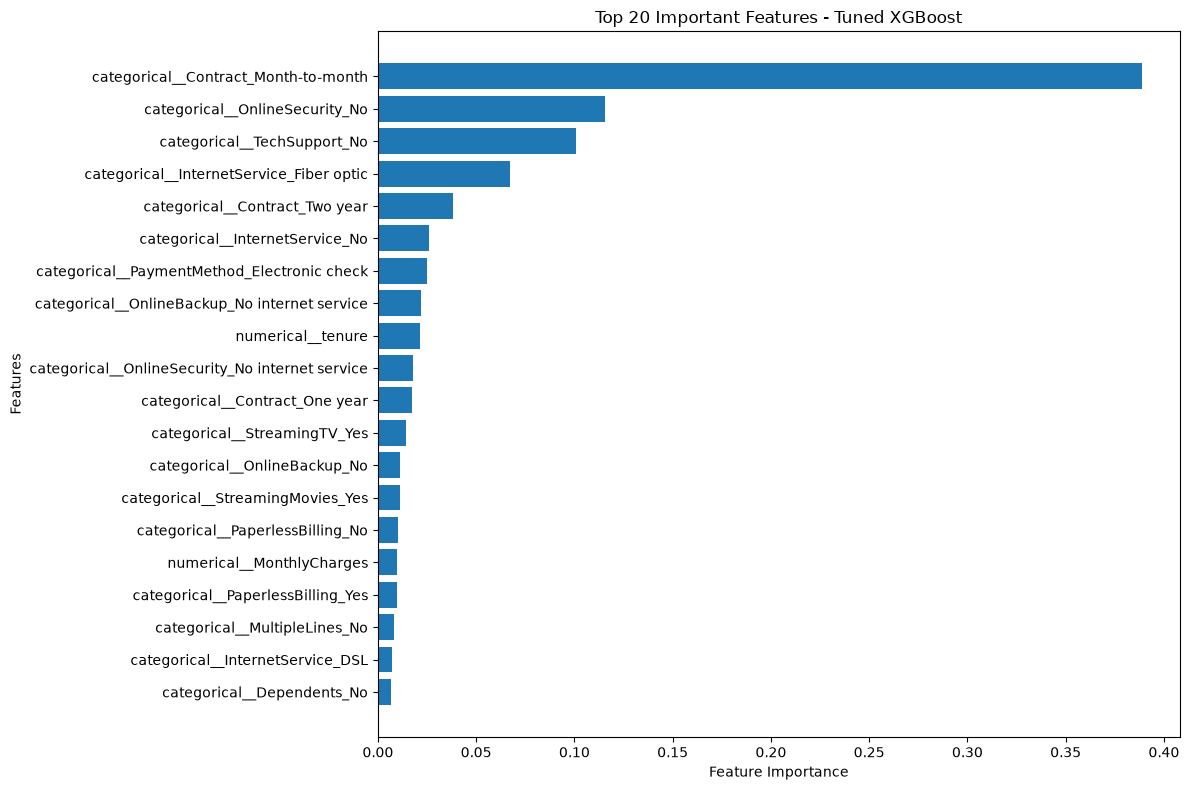

In [11]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 Important Features - Tuned XGBoost")

plt.tight_layout()
plt.show()

In [12]:
# Extract original feature names from transformed feature names
feature_importance["original_feature"] = (
    feature_importance["feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numerical__", "", regex=False)
)

# Aggregate importance by original feature
original_feature_importance = (
    feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(original_feature_importance.head(20))

                      original_feature  importance
0              Contract_Month-to-month    0.388742
1                    OnlineSecurity_No    0.115481
2                       TechSupport_No    0.100834
3          InternetService_Fiber optic    0.066992
4                    Contract_Two year    0.038332
5                   InternetService_No    0.026092
6       PaymentMethod_Electronic check    0.025145
7     OnlineBackup_No internet service    0.022018
8                               tenure    0.021255
9   OnlineSecurity_No internet service    0.018021
10                   Contract_One year    0.017523
11                     StreamingTV_Yes    0.014472
12                     OnlineBackup_No    0.011491
13                 StreamingMovies_Yes    0.011381
14                 PaperlessBilling_No    0.010028
15                      MonthlyCharges    0.009761
16                PaperlessBilling_Yes    0.009667
17                    MultipleLines_No    0.007983
18                 InternetServ

In [ ]:
# Identify numerical and categorical original features
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "TotalCharges"
]

# Map transformed features to their original feature names
def get_original_feature(feature):
    feature = feature.replace("categorical__", "")
    feature = feature.replace("numerical__", "")

    if feature.startswith("num__"):
        feature = feature.replace("num__", "", 1)

    if feature.startswith("cat__"):
        feature = feature.replace("cat__", "", 1)

    for col in numerical_features + categorical_features:
        if feature == col or feature.startswith(col + "_"):
            return col

    return feature

feature_importance["original_feature"] = (
    feature_importance["feature"].apply(get_original_feature)
)

# Aggregate importance
original_feature_importance = (
    feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(original_feature_importance)

                                            feature  importance  \
0              categorical__Contract_Month-to-month    0.388742   
1                    categorical__OnlineSecurity_No    0.115481   
2                       categorical__TechSupport_No    0.100834   
3          categorical__InternetService_Fiber optic    0.066992   
4                    categorical__Contract_Two year    0.038332   
5                   categorical__InternetService_No    0.026092   
6       categorical__PaymentMethod_Electronic check    0.025145   
7     categorical__OnlineBackup_No internet service    0.022018   
8                                 numerical__tenure    0.021255   
9   categorical__OnlineSecurity_No internet service    0.018021   
10                   categorical__Contract_One year    0.017523   
11                     categorical__StreamingTV_Yes    0.014472   
12                     categorical__OnlineBackup_No    0.011491   
13                 categorical__StreamingMovies_Yes    0.01138